In [4]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(i, torch.cuda.get_device_name(i))

PyTorch: 2.10.0+cu128
CUDA: True
GPU count: 2
0 Tesla T4
1 Tesla T4


In [5]:
!nvidia-smi

Fri Sep 11 12:17:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
import os

In [7]:
import pandas as pd

BASE = "/kaggle/input/datasets/gillesokhin/nutrition5k-dataset"

nutrition = pd.read_csv(f"{BASE}/dish_nutrition_values.csv")

print(nutrition.columns.tolist())
display(nutrition.head())

['dish_id', 'calories', 'mass', 'fat', 'carb', 'protein']


,dish_id,calories,mass,fat,carb,protein
0,dish_1561662216,300.794281,193.0,12.387489,28.218290,18.633970
1,dish_1562688426,137.569992,88.0,8.256000,5.190000,10.297000
2,dish_1561662054,419.438782,292.0,23.838249,26.351543,25.910593
3,dish_1562008979,382.936646,290.0,22.224644,10.173570,35.345387
4,dish_1560455030,20.590000,103.0,0.148000,4.625000,0.956000


In [8]:
import os

nutrition["image_path"] = nutrition["dish_id"].apply(
    lambda x: f"{BASE}/imagery/realsense_overhead/{x}/rgb.png"
)

# Chỉ giữ món thực sự có ảnh RGB
nutrition = nutrition[
    nutrition["image_path"].apply(os.path.exists)
].reset_index(drop=True)

print("Số món có ảnh:", len(nutrition))

display(
    nutrition[
        ["dish_id", "image_path", "calories"]
    ].head()
)

Số món có ảnh: 3244


,dish_id,image_path,calories
0,dish_1561662216,/kaggle/input/datasets/gillesokhin/nutrition5k...,300.794281
1,dish_1561662054,/kaggle/input/datasets/gillesokhin/nutrition5k...,419.438782
2,dish_1562008979,/kaggle/input/datasets/gillesokhin/nutrition5k...,382.936646
3,dish_1560455030,/kaggle/input/datasets/gillesokhin/nutrition5k...,20.590000
4,dish_1558372433,/kaggle/input/datasets/gillesokhin/nutrition5k...,74.360001


In [9]:
print(nutrition.columns.tolist())
display(nutrition.head())

['dish_id', 'calories', 'mass', 'fat', 'carb', 'protein', 'image_path']


,dish_id,calories,mass,fat,carb,protein,image_path
0,dish_1561662216,300.794281,193.0,12.387489,28.218290,18.633970,/kaggle/input/datasets/gillesokhin/nutrition5k...
1,dish_1561662054,419.438782,292.0,23.838249,26.351543,25.910593,/kaggle/input/datasets/gillesokhin/nutrition5k...
2,dish_1562008979,382.936646,290.0,22.224644,10.173570,35.345387,/kaggle/input/datasets/gillesokhin/nutrition5k...
3,dish_1560455030,20.590000,103.0,0.148000,4.625000,0.956000,/kaggle/input/datasets/gillesokhin/nutrition5k...
4,dish_1558372433,74.360001,143.0,0.286000,0.429000,20.020000,/kaggle/input/datasets/gillesokhin/nutrition5k...


In [10]:
df = nutrition[
    ["dish_id", "image_path", "calories"]
].copy()

display(df.head())
print("Tổng số mẫu:", len(df))

,dish_id,image_path,calories
0,dish_1561662216,/kaggle/input/datasets/gillesokhin/nutrition5k...,300.794281
1,dish_1561662054,/kaggle/input/datasets/gillesokhin/nutrition5k...,419.438782
2,dish_1562008979,/kaggle/input/datasets/gillesokhin/nutrition5k...,382.936646
3,dish_1560455030,/kaggle/input/datasets/gillesokhin/nutrition5k...,20.590000
4,dish_1558372433,/kaggle/input/datasets/gillesokhin/nutrition5k...,74.360001


Tổng số mẫu: 3244


In [11]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 2270
Val: 487
Test: 487


In [12]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

class NutritionDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        calories = torch.tensor(row["calories"], dtype=torch.float32)

        if self.transform:
            image = self.transform(image)

        return image, calories

In [13]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [14]:
train_dataset = NutritionDataset(train_df, train_transform)
val_dataset = NutritionDataset(val_df, val_transform)
test_dataset = NutritionDataset(test_df, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(len(train_dataset), len(val_dataset), len(test_dataset))

2270 487 487


In [15]:
images, calories = next(iter(train_loader))

print("Images:", images.shape)
print("Calories:", calories.shape)
print("Ví dụ calories:", calories[:5])

Images: torch.Size([64, 3, 224, 224])
Calories: torch.Size([64])
Ví dụ calories: tensor([322.0020,  38.0700, 111.9600, 351.4055, 696.3635])


In [16]:
# Lưu split cố định để mọi experiment sau dùng cùng dữ liệu
train_df.to_csv("/kaggle/working/train.csv", index=False)
val_df.to_csv("/kaggle/working/val.csv", index=False)
test_df.to_csv("/kaggle/working/test.csv", index=False)

print("Saved fixed splits:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Saved fixed splits:
Train: 2270
Validation: 487
Test: 487


In [17]:
# Thống kê mô tả target calories
def calorie_stats(dataframe, split_name):
    return {
        "split": split_name,
        "n_samples": len(dataframe),
        "min_kcal": dataframe["calories"].min(),
        "max_kcal": dataframe["calories"].max(),
        "mean_kcal": dataframe["calories"].mean(),
        "std_kcal": dataframe["calories"].std(),
        "median_kcal": dataframe["calories"].median(),
    }

stats_df = pd.DataFrame([
    calorie_stats(train_df, "Train"),
    calorie_stats(val_df, "Validation"),
    calorie_stats(test_df, "Test"),
    calorie_stats(pd.concat([train_df, val_df, test_df]), "Total"),
])

display(stats_df.round(2))
stats_df.to_csv("/kaggle/working/dataset_calorie_statistics.csv", index=False)


,split,n_samples,min_kcal,max_kcal,mean_kcal,std_kcal,median_kcal
0,Train,2270,0.00,3943.33,253.31,221.40,207.40
1,Validation,487,2.30,1324.08,256.67,212.09,212.16
2,Test,487,1.15,1264.55,266.35,218.93,234.58
3,Total,3244,0.00,3943.33,255.77,219.64,210.32


# EXPERIMENTS

Phần chuẩn bị dữ liệu phía trên được giữ cố định.  
Thêm các experiment mới từ đây trở xuống để bảo đảm tất cả thí nghiệm dùng cùng dataset split.


In [18]:
# ============================================================
# EXPERIMENT 4 - RGB-D FUSION
# Step 1: Add depth paths
# ============================================================

import os

def add_depth_path(dataframe):
    df_out = dataframe.copy()

    df_out["depth_path"] = (
        df_out["image_path"]
        .str.replace("rgb.png", "depth_raw.png", regex=False)
    )

    return df_out


train_df = add_depth_path(train_df)
val_df   = add_depth_path(val_df)
test_df  = add_depth_path(test_df)


def check_depth_coverage(dataframe, name):
    exists = dataframe["depth_path"].apply(os.path.exists)

    print(
        f"{name}: "
        f"{exists.sum()}/{len(dataframe)} depth files "
        f"({exists.mean() * 100:.2f}%)"
    )

    return exists


train_depth_exists = check_depth_coverage(train_df, "Train")
val_depth_exists   = check_depth_coverage(val_df, "Validation")
test_depth_exists  = check_depth_coverage(test_df, "Test")

Train: 2270/2270 depth files (100.00%)
Validation: 487/487 depth files (100.00%)
Test: 486/487 depth files (99.79%)


In [19]:
from PIL import Image
import numpy as np

sample_row = train_df.iloc[0]

depth_img = Image.open(sample_row["depth_path"])
depth_np = np.array(depth_img)

print("Dish ID:", sample_row["dish_id"])
print("Depth path:", sample_row["depth_path"])

print("\n=== DEPTH INFO ===")
print("PIL mode :", depth_img.mode)
print("Shape    :", depth_np.shape)
print("dtype    :", depth_np.dtype)

print("\n=== DEPTH VALUES ===")
print("Min      :", depth_np.min())
print("Max      :", depth_np.max())
print("Mean     :", depth_np.mean())
print("Median   :", np.median(depth_np))

nonzero = depth_np[depth_np > 0]

if len(nonzero) > 0:
    print("\n=== NON-ZERO DEPTH ===")
    print("Count    :", len(nonzero))
    print("Min      :", nonzero.min())
    print("Max      :", nonzero.max())
    print("Mean     :", nonzero.mean())

    print(
        "Percentiles:",
        np.percentile(
            nonzero,
            [1, 5, 25, 50, 75, 95, 99]
        )
    )

Dish ID: dish_1565194781
Depth path: /kaggle/input/datasets/gillesokhin/nutrition5k-dataset/imagery/realsense_overhead/dish_1565194781/depth_raw.png

=== DEPTH INFO ===
PIL mode : I;16
Shape    : (480, 640)
dtype    : uint16

=== DEPTH VALUES ===
Min      : 0
Max      : 32306
Mean     : 3201.4111165364584
Median   : 3464.0

=== NON-ZERO DEPTH ===
Count    : 272834
Min      : 3108
Max      : 32306
Mean     : 3604.6588585000404
Percentiles: [3193. 3248. 3396. 3486. 3818. 4100. 4128.]


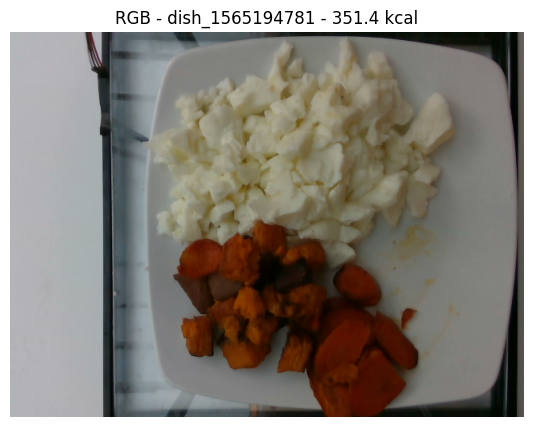

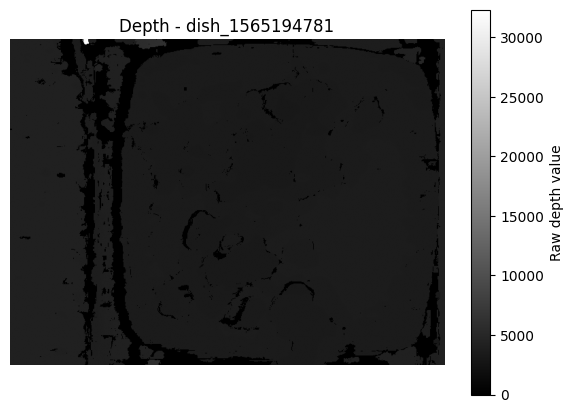

In [20]:
import matplotlib.pyplot as plt

rgb_img = Image.open(
    sample_row["image_path"]
).convert("RGB")

depth_img = Image.open(
    sample_row["depth_path"]
)

plt.figure(figsize=(7, 5))
plt.imshow(rgb_img)
plt.title(
    f"RGB - {sample_row['dish_id']} - "
    f"{sample_row['calories']:.1f} kcal"
)
plt.axis("off")
plt.show()

plt.figure(figsize=(7, 5))
plt.imshow(
    np.array(depth_img),
    cmap="gray"
)
plt.title(
    f"Depth - {sample_row['dish_id']}"
)
plt.colorbar(label="Raw depth value")
plt.axis("off")
plt.show()

In [21]:
train_ids = set(train_df["dish_id"])
val_ids   = set(val_df["dish_id"])
test_ids  = set(test_df["dish_id"])

print(
    "Train ∩ Val :",
    len(train_ids & val_ids)
)

print(
    "Train ∩ Test:",
    len(train_ids & test_ids)
)

print(
    "Val ∩ Test  :",
    len(val_ids & test_ids)
)

Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0


In [22]:
# ============================================================
# EXP 4 - Step 2
# Estimate robust depth range FROM TRAIN ONLY
# ============================================================

import numpy as np
from PIL import Image

rng = np.random.default_rng(42)

sampled_depth = []

for path in train_df["depth_path"]:
    d = np.array(Image.open(path), dtype=np.float32)

    # Bỏ pixel = 0 vì thường là invalid/background
    valid = d[d > 0]

    if len(valid) == 0:
        continue

    # sample tối đa 1000 pixel / ảnh
    n = min(1000, len(valid))

    idx = rng.choice(
        len(valid),
        size=n,
        replace=False
    )

    sampled_depth.append(valid[idx])


sampled_depth = np.concatenate(sampled_depth)

DEPTH_LOW = np.percentile(sampled_depth, 1)
DEPTH_HIGH = np.percentile(sampled_depth, 99)

print("Samples:", len(sampled_depth))
print("P1 :", DEPTH_LOW)
print("P99:", DEPTH_HIGH)
print("Mean:", sampled_depth.mean())
print("Std :", sampled_depth.std())

Samples: 2270000
P1 : 3038.0
P99: 4860.0
Mean: 3754.1558
Std : 924.07886


In [26]:
# ============================================================
# RGB-D Dataset
# ============================================================

import random
import torch

from torch.utils.data import Dataset
from torchvision.transforms import functional as TF
from torchvision import transforms


RGB_NORMALIZE = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)


class NutritionRGBDDataset(Dataset):

    def __init__(
        self,
        dataframe,
        depth_low,
        depth_high,
        train=True
    ):
        self.df = dataframe.reset_index(drop=True)

        self.depth_low = depth_low
        self.depth_high = depth_high

        self.train = train


    def __len__(self):
        return len(self.df)


    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # ---------------------------
        # RGB
        # ---------------------------
        rgb = Image.open(
            row["image_path"]
        ).convert("RGB")

        # ---------------------------
        # DEPTH
        # ---------------------------
        depth = np.array(
            Image.open(row["depth_path"]),
            dtype=np.float32
        )

        # Invalid depth mask
        valid_mask = depth > 0

        # Clip only valid values
        depth_norm = np.zeros_like(
            depth,
            dtype=np.float32
        )

        depth_valid = np.clip(
            depth[valid_mask],
            self.depth_low,
            self.depth_high
        )

        depth_norm[valid_mask] = (
            depth_valid - self.depth_low
        ) / (
            self.depth_high - self.depth_low
        )

        # numpy -> PIL-like tensor
        depth_tensor = torch.from_numpy(
            depth_norm
        ).unsqueeze(0)

        # ---------------------------
        # Resize
        # ---------------------------
        rgb = TF.resize(
            rgb,
            [224, 224]
        )

        depth_tensor = TF.resize(
            depth_tensor,
            [224, 224],
            antialias=True
        )

        # ---------------------------
        # SAME augmentation RGB + D
        # ---------------------------
        if self.train and random.random() < 0.5:

            rgb = TF.hflip(rgb)

            depth_tensor = TF.hflip(
                depth_tensor
            )

        # RGB -> tensor
        rgb = TF.to_tensor(rgb)

        rgb = RGB_NORMALIZE(rgb)

        calories = torch.tensor(
            row["calories"],
            dtype=torch.float32
        )

        return (
            rgb,
            depth_tensor,
            calories
        )

In [28]:
from torch.utils.data import DataLoader

train_rgbd_dataset = NutritionRGBDDataset(
    train_df,
    DEPTH_LOW,
    DEPTH_HIGH,
    train=True
)

val_rgbd_dataset = NutritionRGBDDataset(
    val_df,
    DEPTH_LOW,
    DEPTH_HIGH,
    train=False
)

test_rgbd_dataset = NutritionRGBDDataset(
    test_df,
    DEPTH_LOW,
    DEPTH_HIGH,
    train=False
)


train_rgbd_loader = DataLoader(
    train_rgbd_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_rgbd_loader = DataLoader(
    val_rgbd_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [29]:
rgb, depth, calories = next(
    iter(train_rgbd_loader)
)

print("RGB:", rgb.shape)
print("Depth:", depth.shape)
print("Calories:", calories.shape)

print(
    "Depth range:",
    depth.min().item(),
    depth.max().item()
)

RGB: torch.Size([64, 3, 224, 224])
Depth: torch.Size([64, 1, 224, 224])
Calories: torch.Size([64])
Depth range: 0.0 1.000000238418579


In [30]:
# ============================================================
# RGB-D Fusion Model
# ============================================================

import torch.nn as nn

from torchvision.models import (
    resnet18,
    resnet50,
    ResNet18_Weights,
    ResNet50_Weights
)


class RGBDFusionModel(nn.Module):

    def __init__(self):

        super().__init__()

        # ===========================
        # RGB Encoder
        # ===========================
        self.rgb_encoder = resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        rgb_dim = (
            self.rgb_encoder.fc.in_features
        )

        self.rgb_encoder.fc = nn.Identity()


        # ===========================
        # Depth Encoder
        # ===========================
        self.depth_encoder = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        # Convert first conv:
        # 3 channels -> 1 channel
        old_conv = self.depth_encoder.conv1

        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False
        )

        # Initialize using mean of pretrained
        # RGB convolution weights
        with torch.no_grad():

            new_conv.weight.copy_(
                old_conv.weight.mean(
                    dim=1,
                    keepdim=True
                )
            )

        self.depth_encoder.conv1 = new_conv

        depth_dim = (
            self.depth_encoder.fc.in_features
        )

        self.depth_encoder.fc = nn.Identity()


        # ===========================
        # Fusion Head
        # ===========================
        self.fusion = nn.Sequential(

            nn.Linear(
                rgb_dim + depth_dim,
                512
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                1
            )
        )


    def forward(
        self,
        rgb,
        depth
    ):

        rgb_feature = self.rgb_encoder(
            rgb
        )

        depth_feature = self.depth_encoder(
            depth
        )

        feature = torch.cat(
            [
                rgb_feature,
                depth_feature
            ],
            dim=1
        )

        output = self.fusion(
            feature
        )

        return output

In [32]:
device = torch.device("cuda:0")

model_rgbd = RGBDFusionModel().to(device)

rgb = rgb.to(device)
depth = depth.to(device)

with torch.no_grad():

    output = model_rgbd(
        rgb,
        depth
    )

print("Output:", output.shape)

params = sum(
    p.numel()
    for p in model_rgbd.parameters()
)

print(
    f"Parameters: {params / 1e6:.2f} M"
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s] 


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 141MB/s] 


Output: torch.Size([64, 1])
Parameters: 35.99 M


In [41]:
# ============================================================
# EXP 4A - RGB-D FUSION - 1 GPU - 20 EPOCH
# ============================================================

import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ------------------------------------------------------------
# Clear probe model / tensors
# ------------------------------------------------------------
try:
    del model_rgbd
except:
    pass

try:
    del rgb, depth, output
except:
    pass

gc.collect()
torch.cuda.empty_cache()


# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------
SEED = 42
EPOCHS = 20
LR = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda:0")


# ------------------------------------------------------------
# NEW MODEL FROM SCRATCH
# ------------------------------------------------------------
model_rgbd = RGBDFusionModel().to(device)

criterion = nn.SmoothL1Loss()

optimizer = torch.optim.Adam(
    model_rgbd.parameters(),
    lr=LR
)


# ------------------------------------------------------------
# TRAIN FUNCTION
# ------------------------------------------------------------
def train_one_epoch_rgbd(
    model,
    loader,
    criterion,
    optimizer,
    device
):
    model.train()

    total_loss = 0.0

    for rgb, depth, calories in loader:

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        depth = depth.to(
            device,
            non_blocking=True
        )

        calories = calories.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(
            rgb,
            depth
        ).squeeze(1)

        loss = criterion(
            outputs,
            calories
        )

        loss.backward()
        optimizer.step()

        total_loss += (
            loss.item() * rgb.size(0)
        )

    return (
        total_loss
        / len(loader.dataset)
    )


# ------------------------------------------------------------
# EVALUATION
# ------------------------------------------------------------
def evaluate_rgbd(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0

    preds = []
    targets = []

    with torch.no_grad():

        for rgb, depth, calories in loader:

            rgb = rgb.to(
                device,
                non_blocking=True
            )

            depth = depth.to(
                device,
                non_blocking=True
            )

            calories = calories.to(
                device,
                non_blocking=True
            )

            outputs = model(
                rgb,
                depth
            ).squeeze(1)

            loss = criterion(
                outputs,
                calories
            )

            total_loss += (
                loss.item() * rgb.size(0)
            )

            preds.extend(
                outputs.cpu().numpy()
            )

            targets.extend(
                calories.cpu().numpy()
            )

    preds = np.array(preds)
    targets = np.array(targets)

    mae = np.mean(
        np.abs(preds - targets)
    )

    rmse = np.sqrt(
        np.mean(
            (preds - targets) ** 2
        )
    )

    val_loss = (
        total_loss
        / len(loader.dataset)
    )

    return val_loss, mae, rmse


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------
history_rgbd = []

best_mae = float("inf")
best_rmse = None
best_epoch = None

total_train_time = 0.0
max_train_vram_gb = 0.0


for epoch in range(EPOCHS):

    # --------------------------------
    # TRAIN TIMER + VRAM
    # --------------------------------
    torch.cuda.reset_peak_memory_stats()

    torch.cuda.synchronize()
    start = time.time()

    train_loss = train_one_epoch_rgbd(
        model_rgbd,
        train_rgbd_loader,
        criterion,
        optimizer,
        device
    )

    torch.cuda.synchronize()

    epoch_train_time = (
        time.time() - start
    )

    total_train_time += (
        epoch_train_time
    )

    peak_vram_gb = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    max_train_vram_gb = max(
        max_train_vram_gb,
        peak_vram_gb
    )

    # --------------------------------
    # VALIDATION
    # not included in train time
    # --------------------------------
    val_loss, val_mae, val_rmse = (
        evaluate_rgbd(
            model_rgbd,
            val_rgbd_loader,
            criterion,
            device
        )
    )

    history_rgbd.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_mae": val_mae,
        "val_rmse": val_rmse,
        "train_time_sec": epoch_train_time,
        "peak_vram_gb": peak_vram_gb
    })

    # --------------------------------
    # SAVE BEST
    # --------------------------------
    if val_mae < best_mae:

        best_mae = val_mae
        best_rmse = val_rmse
        best_epoch = epoch + 1

        torch.save(
            model_rgbd.state_dict(),
            "/kaggle/working/"
            "rgbd_fusion_20epoch_1gpu_best.pth"
        )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.2f} | "
        f"MAE: {val_mae:.2f} kcal | "
        f"RMSE: {val_rmse:.2f} kcal | "
        f"Train: {epoch_train_time:.2f}s | "
        f"VRAM: {peak_vram_gb:.2f} GB"
    )


# ------------------------------------------------------------
# SAVE HISTORY
# ------------------------------------------------------------
history_rgbd_df = pd.DataFrame(
    history_rgbd
)

history_rgbd_df.to_csv(
    "/kaggle/working/"
    "rgbd_fusion_20epoch_1gpu_history.csv",
    index=False
)


# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------
throughput = (
    len(train_rgbd_dataset)
    * EPOCHS
    / total_train_time
)

print(
    "\n=== RGB-D FUSION - 1 GPU - 20 EPOCH RESULT ==="
)

print(
    f"Training time: "
    f"{total_train_time:.2f} s"
)

print(
    f"Throughput: "
    f"{throughput:.2f} samples/s"
)

print(
    f"Best epoch: "
    f"{best_epoch}"
)

print(
    f"Best MAE: "
    f"{best_mae:.2f} kcal"
)

print(
    f"Best RMSE: "
    f"{best_rmse:.2f} kcal"
)

print(
    f"Final MAE: "
    f"{history_rgbd[-1]['val_mae']:.2f} kcal"
)

print(
    f"Final RMSE: "
    f"{history_rgbd[-1]['val_rmse']:.2f} kcal"
)

print(
    f"Peak training VRAM: "
    f"{max_train_vram_gb:.2f} GB"
)

Epoch 01/20 | Train Loss: 236.00 | MAE: 154.40 kcal | RMSE: 225.96 kcal | Train: 43.02s | VRAM: 7.36 GB
Epoch 02/20 | Train Loss: 133.42 | MAE: 76.94 kcal | RMSE: 110.11 kcal | Train: 40.87s | VRAM: 7.36 GB
Epoch 03/20 | Train Loss: 70.70 | MAE: 65.19 kcal | RMSE: 103.97 kcal | Train: 38.40s | VRAM: 7.36 GB
Epoch 04/20 | Train Loss: 61.77 | MAE: 57.07 kcal | RMSE: 89.63 kcal | Train: 36.52s | VRAM: 7.36 GB
Epoch 05/20 | Train Loss: 50.72 | MAE: 52.52 kcal | RMSE: 86.16 kcal | Train: 39.82s | VRAM: 7.36 GB
Epoch 06/20 | Train Loss: 47.86 | MAE: 51.22 kcal | RMSE: 80.48 kcal | Train: 39.73s | VRAM: 7.36 GB
Epoch 07/20 | Train Loss: 42.05 | MAE: 54.55 kcal | RMSE: 86.34 kcal | Train: 39.85s | VRAM: 7.36 GB
Epoch 08/20 | Train Loss: 42.27 | MAE: 47.03 kcal | RMSE: 76.28 kcal | Train: 39.87s | VRAM: 7.36 GB
Epoch 09/20 | Train Loss: 36.60 | MAE: 46.94 kcal | RMSE: 75.74 kcal | Train: 37.93s | VRAM: 7.36 GB
Epoch 10/20 | Train Loss: 37.06 | MAE: 47.32 kcal | RMSE: 73.90 kcal | Train: 40.42s 

In [42]:
import json

depth_config = {
    "DEPTH_LOW": float(DEPTH_LOW),
    "DEPTH_HIGH": float(DEPTH_HIGH)
}

with open("/kaggle/working/depth_config.json", "w") as f:
    json.dump(depth_config, f)

print(depth_config)

{'DEPTH_LOW': 3038.0, 'DEPTH_HIGH': 4860.0}


In [43]:
%%writefile /kaggle/working/train_rgbd_ddp.py

import os
import json
import time
import random
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.distributed as dist

from torch.utils.data import Dataset, DataLoader
from torch.utils.data.distributed import DistributedSampler
from torch.nn.parallel import DistributedDataParallel as DDP

from torchvision import transforms
from torchvision.transforms import functional as TF
from torchvision.models import (
    resnet18,
    resnet50,
    ResNet18_Weights,
    ResNet50_Weights
)


# ============================================================
# CONFIG
# ============================================================
SEED = 42
EPOCHS = 20
LOCAL_BATCH_SIZE = 32       # 32 x 2 GPU = global batch 64
LR = 1e-4

with open("/kaggle/working/depth_config.json") as f:
    cfg = json.load(f)

DEPTH_LOW = cfg["DEPTH_LOW"]
DEPTH_HIGH = cfg["DEPTH_HIGH"]


RGB_NORMALIZE = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)


# ============================================================
# DATASET
# ============================================================
class NutritionRGBDDataset(Dataset):

    def __init__(
        self,
        dataframe,
        depth_low,
        depth_high,
        train=True
    ):
        self.df = dataframe.reset_index(drop=True)
        self.depth_low = depth_low
        self.depth_high = depth_high
        self.train = train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        rgb = Image.open(
            row["image_path"]
        ).convert("RGB")

        depth = np.array(
            Image.open(row["depth_path"]),
            dtype=np.float32
        )

        valid_mask = depth > 0

        depth_norm = np.zeros_like(
            depth,
            dtype=np.float32
        )

        depth_valid = np.clip(
            depth[valid_mask],
            self.depth_low,
            self.depth_high
        )

        depth_norm[valid_mask] = (
            depth_valid - self.depth_low
        ) / (
            self.depth_high - self.depth_low
        )

        depth_tensor = torch.from_numpy(
            depth_norm
        ).unsqueeze(0)

        rgb = TF.resize(
            rgb,
            [224, 224]
        )

        depth_tensor = TF.resize(
            depth_tensor,
            [224, 224],
            antialias=True
        )

        # SAME augmentation for RGB and depth
        if self.train and random.random() < 0.5:
            rgb = TF.hflip(rgb)
            depth_tensor = TF.hflip(depth_tensor)

        rgb = TF.to_tensor(rgb)
        rgb = RGB_NORMALIZE(rgb)

        calories = torch.tensor(
            row["calories"],
            dtype=torch.float32
        )

        return rgb, depth_tensor, calories


# ============================================================
# MODEL
# ============================================================
class RGBDFusionModel(nn.Module):

    def __init__(self):

        super().__init__()

        # RGB branch
        self.rgb_encoder = resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        rgb_dim = self.rgb_encoder.fc.in_features
        self.rgb_encoder.fc = nn.Identity()

        # Depth branch
        self.depth_encoder = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        old_conv = self.depth_encoder.conv1

        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False
        )

        with torch.no_grad():
            new_conv.weight.copy_(
                old_conv.weight.mean(
                    dim=1,
                    keepdim=True
                )
            )

        self.depth_encoder.conv1 = new_conv

        depth_dim = self.depth_encoder.fc.in_features
        self.depth_encoder.fc = nn.Identity()

        # Fusion
        self.fusion = nn.Sequential(
            nn.Linear(
                rgb_dim + depth_dim,
                512
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, rgb, depth):

        rgb_feature = self.rgb_encoder(rgb)
        depth_feature = self.depth_encoder(depth)

        feature = torch.cat(
            [rgb_feature, depth_feature],
            dim=1
        )

        return self.fusion(feature)


# ============================================================
# EVALUATE
# ============================================================
def evaluate(model, loader, device):

    model.eval()

    preds = []
    targets = []

    with torch.no_grad():

        for rgb, depth, calories in loader:

            rgb = rgb.to(
                device,
                non_blocking=True
            )

            depth = depth.to(
                device,
                non_blocking=True
            )

            calories = calories.to(
                device,
                non_blocking=True
            )

            outputs = model(
                rgb,
                depth
            ).squeeze(1)

            preds.extend(
                outputs.cpu().numpy()
            )

            targets.extend(
                calories.cpu().numpy()
            )

    preds = np.array(preds)
    targets = np.array(targets)

    mae = np.mean(
        np.abs(preds - targets)
    )

    rmse = np.sqrt(
        np.mean(
            (preds - targets) ** 2
        )
    )

    return mae, rmse


# ============================================================
# MAIN
# ============================================================
def main():

    dist.init_process_group("nccl")

    rank = dist.get_rank()
    local_rank = int(os.environ["LOCAL_RANK"])
    world_size = dist.get_world_size()

    torch.cuda.set_device(local_rank)

    device = torch.device(
        f"cuda:{local_rank}"
    )

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    # --------------------------------------------------------
    # DATA
    # --------------------------------------------------------
    train_df = pd.read_csv(
        "/kaggle/working/train_rgbd.csv"
    )

    val_df = pd.read_csv(
        "/kaggle/working/val_rgbd.csv"
    )

    train_dataset = NutritionRGBDDataset(
        train_df,
        DEPTH_LOW,
        DEPTH_HIGH,
        train=True
    )

    val_dataset = NutritionRGBDDataset(
        val_df,
        DEPTH_LOW,
        DEPTH_HIGH,
        train=False
    )

    train_sampler = DistributedSampler(
        train_dataset,
        num_replicas=world_size,
        rank=rank,
        shuffle=True,
        seed=SEED
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=LOCAL_BATCH_SIZE,
        sampler=train_sampler,
        num_workers=2,
        pin_memory=True
    )

    if rank == 0:
        val_loader = DataLoader(
            val_dataset,
            batch_size=64,
            shuffle=False,
            num_workers=2,
            pin_memory=True
        )

    # --------------------------------------------------------
    # MODEL
    # --------------------------------------------------------
    model = RGBDFusionModel().to(device)

    model = DDP(
        model,
        device_ids=[local_rank]
    )

    criterion = nn.SmoothL1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------
    total_train_time = 0.0

    best_mae = float("inf")
    best_rmse = None
    best_epoch = None

    final_mae = None
    final_rmse = None

    history = []

    max_vram_gb = 0.0

    for epoch in range(EPOCHS):

        train_sampler.set_epoch(epoch)

        model.train()

        torch.cuda.reset_peak_memory_stats()

        dist.barrier()
        torch.cuda.synchronize()

        start = time.time()

        total_loss = 0.0

        for rgb, depth, calories in train_loader:

            rgb = rgb.to(
                device,
                non_blocking=True
            )

            depth = depth.to(
                device,
                non_blocking=True
            )

            calories = calories.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            outputs = model(
                rgb,
                depth
            ).squeeze(1)

            loss = criterion(
                outputs,
                calories
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        torch.cuda.synchronize()
        dist.barrier()

        epoch_train_time = (
            time.time() - start
        )

        total_train_time += epoch_train_time

        # local GPU peak memory
        local_vram = torch.tensor(
            torch.cuda.max_memory_allocated()
            / 1024**3,
            device=device
        )

        # get max VRAM among GPUs
        dist.all_reduce(
            local_vram,
            op=dist.ReduceOp.MAX
        )

        epoch_vram = local_vram.item()

        max_vram_gb = max(
            max_vram_gb,
            epoch_vram
        )

        # ----------------------------------------------------
        # VALIDATION
        # not included in training time
        # ----------------------------------------------------
        if rank == 0:

            mae, rmse = evaluate(
                model.module,
                val_loader,
                device
            )

            final_mae = mae
            final_rmse = rmse

            if mae < best_mae:

                best_mae = mae
                best_rmse = rmse
                best_epoch = epoch + 1

                torch.save(
                    model.module.state_dict(),
                    "/kaggle/working/"
                    "rgbd_fusion_20epoch_2gpu_ddp_best.pth"
                )

            history.append({
                "epoch": epoch + 1,
                "val_mae": mae,
                "val_rmse": rmse,
                "train_time_sec": epoch_train_time,
                "peak_vram_per_gpu_gb": epoch_vram
            })

            print(
                f"Epoch {epoch+1:02d}/{EPOCHS} | "
                f"MAE: {mae:.2f} kcal | "
                f"RMSE: {rmse:.2f} kcal | "
                f"Train: {epoch_train_time:.2f}s | "
                f"VRAM/GPU: {epoch_vram:.2f} GB"
            )

        dist.barrier()

    # --------------------------------------------------------
    # RESULT
    # --------------------------------------------------------
    if rank == 0:

        throughput = (
            len(train_dataset)
            * EPOCHS
            / total_train_time
        )

        pd.DataFrame(history).to_csv(
            "/kaggle/working/"
            "rgbd_fusion_20epoch_2gpu_history.csv",
            index=False
        )

        print(
            "\n=== RGB-D FUSION - 2 GPU DDP - "
            "20 EPOCH RESULT ==="
        )

        print(
            f"Training time: "
            f"{total_train_time:.2f} s"
        )

        print(
            f"Throughput: "
            f"{throughput:.2f} samples/s"
        )

        print(
            f"Best epoch: "
            f"{best_epoch}"
        )

        print(
            f"Best MAE: "
            f"{best_mae:.2f} kcal"
        )

        print(
            f"Best RMSE: "
            f"{best_rmse:.2f} kcal"
        )

        print(
            f"Final MAE: "
            f"{final_mae:.2f} kcal"
        )

        print(
            f"Final RMSE: "
            f"{final_rmse:.2f} kcal"
        )

        print(
            f"Peak VRAM per GPU: "
            f"{max_vram_gb:.2f} GB"
        )

    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing /kaggle/working/train_rgbd_ddp.py


In [44]:
!torchrun \
    --standalone \
    --nproc_per_node=2 \
    /kaggle/working/train_rgbd_ddp.py

W0911 12:57:42.028000 666 torch/distributed/run.py:852] 
W0911 12:57:42.028000 666 torch/distributed/run.py:852] *****************************************
W0911 12:57:42.028000 666 torch/distributed/run.py:852] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W0911 12:57:42.028000 666 torch/distributed/run.py:852] *****************************************
[W911 12:57:42.047063740 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[W911 12:57:45.580047606 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[W911 12:57:45.600868887 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3
/usr/local/lib/python3.12/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can sp